In [7]:
!pip install opencv-python numpy pandas matplotlib seaborn

   ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
   ----- ---------------------------------- 1.8/12.9 MB 11.2 MB/s eta 0:00:01
   ------------- -------------------------- 4.5/12.9 MB 11.2 MB/s eta 0:00:01
   --------------------- ------------------ 7.1/12.9 MB 11.8 MB/s eta 0:00:01
   -------------------------- ------------- 8.7/12.9 MB 10.7 MB/s eta 0:00:01
   ---------------------------------- ----- 11.0/12.9 MB 10.7 MB/s eta 0:00:01
   ---------------------------------------- 12.9/12.9 MB 10.5 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorboard 2.10.1 requires protobuf<3.20,>=3.9.2, but you have protobuf 3.20.3 which is incompatible.
tensorflow 2.10.1 requires protobuf<3.20,>=3.9.2, but you have protobuf 3.20.3 which is incompatible.

[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
pip install --upgrade numpy pandas pyarrow

  Using cached pandas-2.3.3-cp310-cp310-win_amd64.whl.metadata (19 kB)
Using cached pandas-2.3.3-cp310-cp310-win_amd64.whl (11.3 MB)
   ---------------------------------------- 0.0/27.3 MB ? eta -:--:--
   --- ------------------------------------ 2.1/27.3 MB 13.0 MB/s eta 0:00:02
   ------- -------------------------------- 5.0/27.3 MB 14.4 MB/s eta 0:00:02
   ---------- ----------------------------- 7.3/27.3 MB 12.9 MB/s eta 0:00:02
   ------------- -------------------------- 9.2/27.3 MB 11.9 MB/s eta 0:00:02
   ---------------- ----------------------- 11.3/27.3 MB 11.4 MB/s eta 0:00:02
   ------------------- -------------------- 13.1/27.3 MB 10.8 MB/s eta 0:00:02
   --------------------- ------------------ 14.9/27.3 MB 10.6 MB/s eta 0:00:02
   ------------------------- -------------- 17.0/27.3 MB 10.5 MB/s eta 0:00:01
   ---------------------------- ----------- 19.1/27.3 MB 10.3 MB/s eta 0:00:01
   ------------------------------- -------- 21.2/27.3 MB 10.2 MB/s eta 0:00:01
   --------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Konfigurasi Tema Visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [8]:
# Path Root Dataset (Sesuai dengan direktori )
DATASET_PATH = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi - Coding\V2 - Dataset"
CLASSES = ['Cendol', 'CK', 'SMP DW', 'SMP UP']

# 1. Persiapan & Pra-pemrosesan Data

## 1.1. Load Data

In [9]:

data_info = []
count = 1
for class_name in CLASSES:
    class_path = os.path.join(DATASET_PATH, class_name)
    if not os.path.exists(class_path):
        continue
        
    for file in os.listdir(class_path):
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            file_path = os.path.join(class_path, file)
            
            # Membaca dimensi tanpa harus meload keseluruhan gambar (lebih cepat)
            # Namun kita pakai cv2.imread untuk mengambil data brightness juga
            img = cv2.imread(file_path)
            if img is not None:
                h, w, _ = img.shape
                orientation = 'Portrait' if h >= w else 'Landscape'
                
                # Hitung rata-rata kecerahan (brightness)
                # Berguna untuk menganalisis pantulan es/lampu cold storage
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                brightness = np.mean(gray)
                
                data_info.append({
                    'Class': class_name,
                    'Filename': file,
                    'Width': w,
                    'Height': h,
                    'Orientation': orientation,
                    'Brightness': brightness,
                    'Path': file_path
                })
                print(f"Berhasil Selesai Get Data Image ke {count}")
                count+=1

df = pd.DataFrame(data_info)
print(f"Total gambar yang berhasil dibaca: {len(df)}")

Berhasil Selesai Get Data Image ke 1
Berhasil Selesai Get Data Image ke 2
Berhasil Selesai Get Data Image ke 3
Berhasil Selesai Get Data Image ke 4
Berhasil Selesai Get Data Image ke 5
Berhasil Selesai Get Data Image ke 6
Berhasil Selesai Get Data Image ke 7
Berhasil Selesai Get Data Image ke 8
Berhasil Selesai Get Data Image ke 9
Berhasil Selesai Get Data Image ke 10
Berhasil Selesai Get Data Image ke 11
Berhasil Selesai Get Data Image ke 12
Berhasil Selesai Get Data Image ke 13
Berhasil Selesai Get Data Image ke 14
Berhasil Selesai Get Data Image ke 15
Berhasil Selesai Get Data Image ke 16
Berhasil Selesai Get Data Image ke 17
Berhasil Selesai Get Data Image ke 18
Berhasil Selesai Get Data Image ke 19
Berhasil Selesai Get Data Image ke 20
Berhasil Selesai Get Data Image ke 21
Berhasil Selesai Get Data Image ke 22
Berhasil Selesai Get Data Image ke 23
Berhasil Selesai Get Data Image ke 24
Berhasil Selesai Get Data Image ke 25
Berhasil Selesai Get Data Image ke 26
Berhasil Selesai Get 

## 1.2. Visualisasi Distribusi Kelas (Class Imbalance)

In [5]:
class_counts = df['Class'].value_counts()
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")
plt.title("Distribusi Jumlah Citra per Varian Cumi", fontsize=14, fontweight='bold')
plt.xlabel("Jenis Cumi", fontsize=12)
plt.ylabel("Jumlah Gambar", fontsize=12)

# Menambahkan angka di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 9), textcoords='offset points')

plt.show()

NameError: name 'df' is not defined

Membuat visualisasi distribusi kelas (Hanya Pie Chart)...


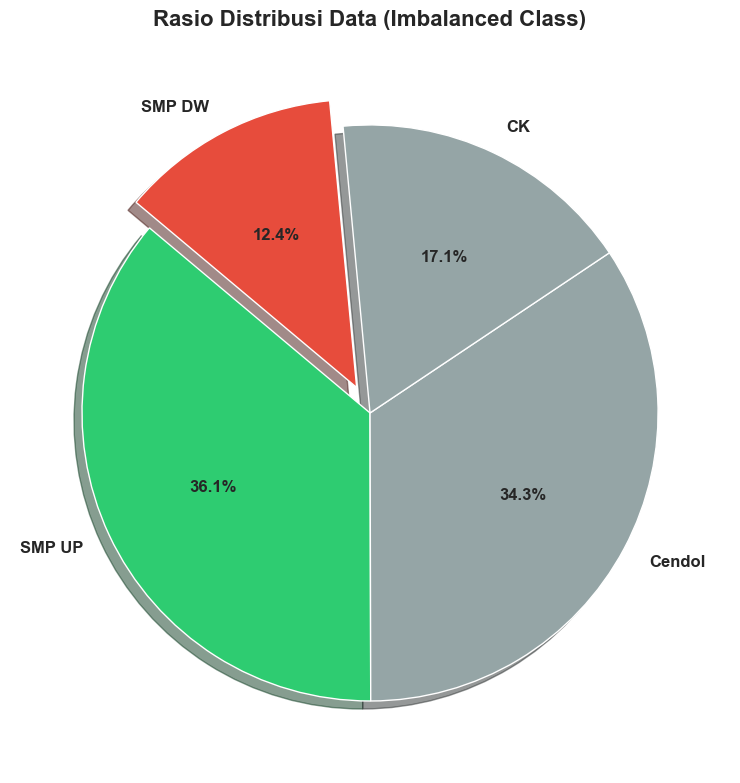


--- Kesimpulan Ketimpangan Data ---
Kelas Mayoritas : SMP UP (843 gambar)
Kelas Minoritas : SMP DW (289 gambar)
Rasio Ketimpangan : Mayoritas 2.9 kali lipat lebih banyak dari Minoritas.


In [24]:
import matplotlib.pyplot as plt

print("Membuat visualisasi distribusi kelas (Hanya Pie Chart)...")

# Menghitung jumlah gambar per kelas (diurutkan dari terbanyak ke terdikit)
class_counts = df['Class'].value_counts()

# Mencari nilai tertinggi (mayoritas) dan terendah (minoritas)
max_count = class_counts.max()
min_count = class_counts.min()

# ---------------------------------------------------------
# Logika Pewarnaan (Color Coding) untuk menyoroti disparitas
# ---------------------------------------------------------
colors = []
for count in class_counts.values:
    if count == max_count:
        colors.append('#2ecc71')  # Emerald Green (Mayoritas / Dominan)
    elif count == min_count:
        colors.append('#e74c3c')  # Alizarin Red (Minoritas / Paling Sedikit)
    else:
        colors.append('#95a5a6')  # Concrete Gray (Netral)

# Menyiapkan kanvas khusus untuk Pie Chart
plt.figure(figsize=(8, 8))
plt.title('Rasio Distribusi Data (Imbalanced Class)', fontsize=16, fontweight='bold', pad=20)

# Menarik keluar potongan pie khusus untuk kelas minoritas agar menjadi pusat perhatian
explode = [0.1 if count == min_count else 0 for count in class_counts.values]

# ==========================================
# PEMBUATAN PIE CHART
# ==========================================
plt.pie(class_counts.values, 
        labels=class_counts.index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors, 
        explode=explode, 
        shadow=True,
        textprops={'fontsize': 12, 'fontweight': 'bold'},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1})

# Menyempurnakan layout agar rapi
plt.tight_layout()

# Menyimpan grafik sebagai file gambar beresolusi tinggi (300 DPI)
plt.savefig('grafik_pie_distribusi_kelas.png', dpi=300, bbox_inches='tight')

# Menampilkan ke layar Jupyter
plt.show()

# Mencetak analisis teks otomatis
print("\n--- Kesimpulan Ketimpangan Data ---")
print(f"Kelas Mayoritas : {class_counts.idxmax()} ({max_count} gambar)")
print(f"Kelas Minoritas : {class_counts.idxmin()} ({min_count} gambar)")
print(f"Rasio Ketimpangan : Mayoritas {round(max_count/min_count, 1)} kali lipat lebih banyak dari Minoritas.")

## 1.3. Analisis Orientasi (Landscape vs Portrait)

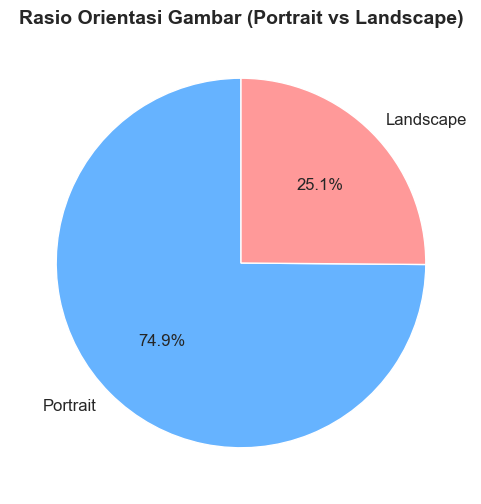

In [18]:
orientation_counts = df['Orientation'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(orientation_counts, labels=orientation_counts.index, autopct='%1.1f%%', 
        colors=['#66b3ff', '#ff9999'], startangle=90, textprops={'fontsize': 12})
plt.title("Rasio Orientasi Gambar (Portrait vs Landscape)", fontsize=14, fontweight='bold')
plt.show()

## 1.4. Analisis Kecerahan Visual (Kondisi Cold Storage)

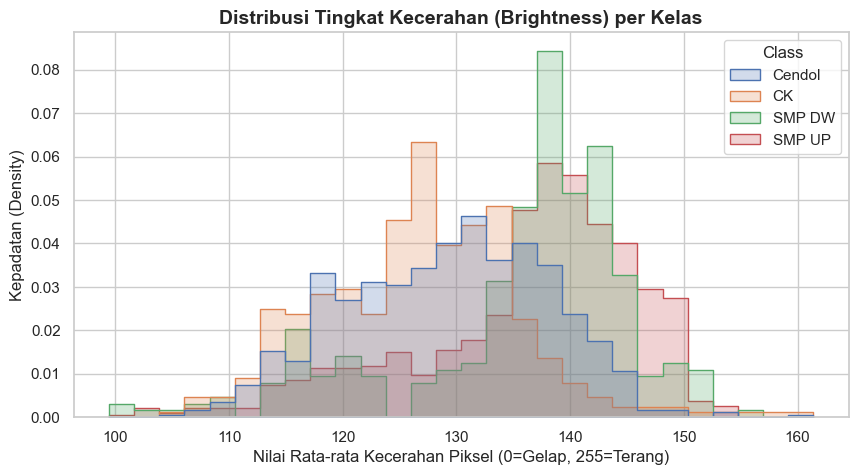

In [19]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Brightness', hue='Class', element="step", stat="density", common_norm=False)
plt.title("Distribusi Tingkat Kecerahan (Brightness) per Kelas", fontsize=14, fontweight='bold')
plt.xlabel("Nilai Rata-rata Kecerahan Piksel (0=Gelap, 255=Terang)", fontsize=12)
plt.ylabel("Kepadatan (Density)", fontsize=12)
plt.show()

## 1.5. Inspeksi Visual Sampel Acak

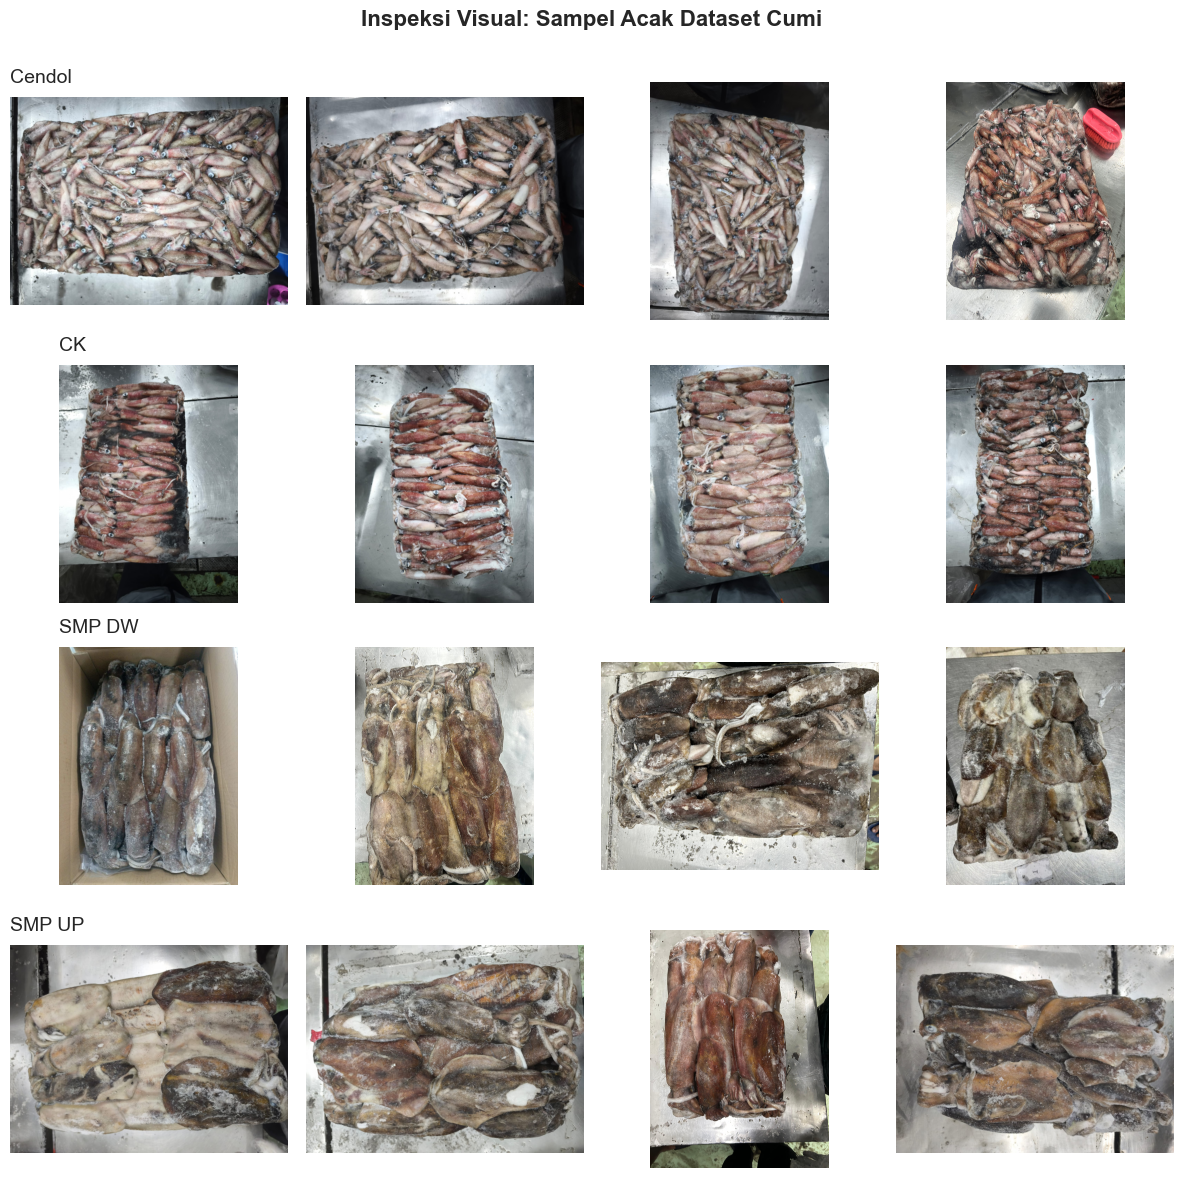

In [20]:
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
fig.suptitle("Inspeksi Visual: Sampel Acak Dataset Cumi", fontsize=16, fontweight='bold')

for i, class_name in enumerate(CLASSES):
    # Ambil 4 sampel acak untuk setiap kelas
    sample_df = df[df['Class'] == class_name].sample(4, replace=True)
    
    for j, (_, row) in enumerate(sample_df.iterrows()):
        img = cv2.imread(row['Path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Ubah BGR ke RGB untuk Matplotlib
        
        ax = axes[i, j]
        ax.imshow(img)
        ax.axis('off')
        if j == 0:
            ax.set_title(class_name, fontsize=14, loc='left', pad=10)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

## 1.6 Otomatisasi Preprocessing (Auto-Rotate & Smart Crop)

In [12]:
import cv2
import os
import numpy as np
from rembg import remove, new_session
from tqdm import tqdm

In [ ]:
!pip install rembg opencv-python tqdm numpy

In [ ]:
!pip install onnxruntime-gpu

In [24]:
PATH_INPUT = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V2 - Dataset"
PATH_OUTPUT = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V3 - Preprocessed Dataset"
CLASSES = ['SMP DW', 'SMP UP']

>Using CPU

In [18]:
def smart_crop_rembg(img):
    # Dapatkan gambar tanpa background (RGBA)
    # rembg akan otomatis mendeteksi objek utama (blok cumi)
    output_rgba = remove(img)
    
    # Ambil channel Alpha (masking)
    alpha_channel = output_rgba[:, :, 3]
    
    # Cari contour dari area yang bukan transparent
    contours, _ = cv2.findContours(alpha_channel, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if contours:
        # Ambil area terbesar (asumsi ini adalah blok cumi utama)
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, box_w, box_h = cv2.boundingRect(largest_contour)
        
        # Tambahkan Margin agar ujung cumi tidak terpotong terlalu mepet
        margin = 30
        x = max(0, x - margin)
        y = max(0, y - margin)
        box_w = min(img.shape[1] - x, box_w + (2 * margin))
        box_h = min(img.shape[0] - y, box_h + (2 * margin))
        
        # Crop dari gambar BGR ASLI (agar background di sekitar sisa crop tetap utuh, bukan transparan)
        return img[y:y+box_h, x:x+box_w]
    
    return img # Fallback ke gambar asli jika AI gagal mendeteksi objek

# ==========================================
# FUNGSI UTAMA PREPROCESSING
# ==========================================
def preprocess_images():
    print("=== Memulai Preprocessing (Auto-Rotate & Smart Crop with Rembg) ===")
    
    # Buat folder output utama jika belum ada
    if not os.path.exists(PATH_OUTPUT):
        os.makedirs(PATH_OUTPUT)

    for class_name in CLASSES:
        input_dir = os.path.join(PATH_INPUT, class_name)
        output_dir = os.path.join(PATH_OUTPUT, class_name)
        
        # Cek ketersediaan folder input
        if not os.path.exists(input_dir):
            print(f"Melewati {class_name}, folder input tidak ditemukan di: {input_dir}")
            continue
            
        # Buat folder output untuk kelas ini jika belum ada
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)
            
        # Kumpulkan semua file gambar
        images = [f for f in os.listdir(input_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        print(f"\nMemproses Kelas: {class_name} ({len(images)} gambar)")
        
        # Proses setiap gambar dengan loading bar (tqdm)
        for img_name in tqdm(images):
            img_path = os.path.join(input_dir, img_name)
            img = cv2.imread(img_path)
            
            # Lewati jika gambar rusak atau tidak terbaca
            if img is None: 
                continue
                
            # 1. AUTO-ROTATE (Landscape ke Portrait)
            h, w = img.shape[:2]
            if w > h:
                img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
            
            # 2. SMART CROP (rembg)
            final_img = smart_crop_rembg(img)
            
            # 3. SIMPAN HASIL
            save_path = os.path.join(output_dir, img_name)
            cv2.imwrite(save_path, final_img)

    print("\nPreprocessing Selesai! Data tersimpan di V3 - Preprocessed Dataset")

In [19]:
if __name__ == "__main__":
    preprocess_images()

=== Memulai Preprocessing (Auto-Rotate & Smart Crop with Rembg) ===

Memproses Kelas: Cendol (801 gambar)


100%|██████████| 801/801 [28:24<00:00,  2.13s/it]



Memproses Kelas: SMP DW (289 gambar)


 13%|█▎        | 37/289 [01:43<11:42,  2.79s/it]


KeyboardInterrupt: 

In [20]:
import onnxruntime as ort

print("Device aktif:", ort.get_device())
print("Provider yang tersedia:", ort.get_available_providers())

Device aktif: GPU
Provider yang tersedia: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


> Using GPU

In [25]:
# ==========================================
# INISIALISASI SESSION GPU (SANGAT PENTING!)
# ==========================================
# Kita paksa rembg untuk menggunakan CUDA (GPU NVIDIA)
providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
# Buka session SATU KALI saja di awal menggunakan model default 'u2net'
session = new_session("u2net", providers=providers)

In [26]:

# ==========================================
# FUNGSI SMART CROP
# ==========================================
def smart_crop_rembg(img, ai_session):
    # Lakukan remove background dengan melempar session GPU yang sudah disiapkan
    output_rgba = remove(img, session=ai_session)
    
    # Ambil channel Alpha (masking)
    alpha_channel = output_rgba[:, :, 3]
    
    # Cari contour
    contours, _ = cv2.findContours(alpha_channel, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, box_w, box_h = cv2.boundingRect(largest_contour)
        
        margin = 30
        x = max(0, x - margin)
        y = max(0, y - margin)
        box_w = min(img.shape[1] - x, box_w + (2 * margin))
        box_h = min(img.shape[0] - y, box_h + (2 * margin))
        
        return img[y:y+box_h, x:x+box_w]
    
    return img

# ==========================================
# FUNGSI UTAMA PREPROCESSING
# ==========================================
def preprocess_images():
    print("=== Memulai Preprocessing GPU-Accelerated ===")
    
    if not os.path.exists(PATH_OUTPUT):
        os.makedirs(PATH_OUTPUT)

    for class_name in CLASSES:
        input_dir = os.path.join(PATH_INPUT, class_name)
        output_dir = os.path.join(PATH_OUTPUT, class_name)
        
        if not os.path.exists(input_dir):
            continue
            
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)
            
        images = [f for f in os.listdir(input_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        print(f"\nMemproses Kelas: {class_name} ({len(images)} gambar)")
        
        for img_name in tqdm(images):
            img_path = os.path.join(input_dir, img_name)
            img = cv2.imread(img_path)
            
            if img is None: 
                continue
                
            h, w = img.shape[:2]
            if w > h:
                img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
            
            # Panggil fungsi dengan menyertakan session GPU
            final_img = smart_crop_rembg(img, session)
            
            save_path = os.path.join(output_dir, img_name)
            cv2.imwrite(save_path, final_img)

    print("\nPreprocessing Selesai!")

In [27]:
if __name__ == "__main__":
    preprocess_images()

=== Memulai Preprocessing GPU-Accelerated ===

Memproses Kelas: SMP DW (289 gambar)


100%|██████████| 289/289 [06:20<00:00,  1.32s/it]



Memproses Kelas: SMP UP (843 gambar)


100%|██████████| 843/843 [17:49<00:00,  1.27s/it]


Preprocessing Selesai!


## 1.7 Data Splitting (Train, Validation, Test)

In [11]:
import os
import shutil
from sklearn.model_selection import train_test_split
from tqdm import tqdm

In [3]:
PATH_SOURCE = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V3 - Preprocessed Dataset"
PATH_DEST = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset"
CLASSES = ['Cendol', 'CK', 'SMP DW', 'SMP UP']

In [2]:
# Rasio: 70% Train, 15% Val, 15% Test
TEST_SIZE = 0.15
VAL_SIZE_RELATIVE = 0.1765 # Menghasilkan tepat 15% dari total awal (0.15 / 0.85)

def split_dataset():
    print("=== Memulai Data Splitting (Stratified Split) ===")
    
    # Membuat struktur folder tujuan (V4)
    for split in ['train', 'val', 'test']:
        for class_name in CLASSES:
            os.makedirs(os.path.join(PATH_DEST, split, class_name), exist_ok=True)

    for class_name in CLASSES:
        class_dir = os.path.join(PATH_SOURCE, class_name)
        if not os.path.exists(class_dir):
            print(f"Melewati {class_name}, folder tidak ditemukan.")
            continue
            
        # Mengambil daftar file (mendukung format campuran dari V3)
        images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        if len(images) == 0:
            continue
            
        print(f"\nMembagi Kelas: {class_name} (Total: {len(images)} gambar)")
        
        # Split 1: Memisahkan Test set (15%)
        train_val_imgs, test_imgs = train_test_split(
            images, test_size=TEST_SIZE, random_state=42, shuffle=True
        )
        
        # Split 2: Memisahkan Val set (15%) dari sisa Train_Val
        train_imgs, val_imgs = train_test_split(
            train_val_imgs, test_size=VAL_SIZE_RELATIVE, random_state=42, shuffle=True
        )
        
        # Fungsi internal untuk proses penyalinan file
        def copy_files(file_list, split_group):
            destination = os.path.join(PATH_DEST, split_group, class_name)
            for img_name in tqdm(file_list, desc=f"Menyalin ke {split_group}", leave=False):
                shutil.copy2(os.path.join(class_dir, img_name), os.path.join(destination, img_name))

        copy_files(train_imgs, 'train')
        copy_files(val_imgs, 'val')
        copy_files(test_imgs, 'test')
        
        print(f"Hasil {class_name} -> Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

    print("\nData Splitting Selesai! Dataset siap digunakan di folder V4.")

In [ ]:
if __name__ == "__main__":
    split_dataset()

=== Memulai Data Splitting (Stratified Split) ===

Membagi Kelas: Cendol (Total: 801 gambar)


Hasil Cendol -> Train: 559 | Val: 121 | Test: 121

Membagi Kelas: CK (Total: 398 gambar)


Hasil CK -> Train: 278 | Val: 60 | Test: 60

Membagi Kelas: SMP DW (Total: 289 gambar)


Hasil SMP DW -> Train: 201 | Val: 44 | Test: 44

Membagi Kelas: SMP UP (Total: 843 gambar)


Hasil SMP UP -> Train: 589 | Val: 127 | Test: 127

Data Splitting Selesai! Dataset siap digunakan di folder V4.


: 

# Fase 2: Skenario Penanganan Imbalance Data

In [ ]:
!pip install albumentations

In [10]:
import os
import cv2
import random
import albumentations as A
from tqdm import tqdm

In [1]:
# ==========================================
# KONFIGURASI PATH
# ==========================================
# Path sumber data latih asli
PATH_TRAIN_ASLI = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset\train"

# Path tujuan untuk menyimpan data hasil sintesis/augmentasi
PATH_TRAIN_AUG = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset\train_augmented_sintesis"
PATH_TRAIN_GAN = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset\train_gan_sintesis"

CLASSES_TO_AUGMENT = ['SMP DW', 'CK']

# Target total gambar yang diinginkan (Asli + Sintesis = Target)
TARGET_TOTAL_TRAIN_COUNT = 600

## 2.1 Sintesis Gambar dengan Standar Augmentasi 

In [7]:
# ==========================================
# PIPELINE AUGMENTASI
# Sesuai dengan kondisi riil saat klasifikasi bahan baku
# (Posisi cumi acak, terbolak-balik, dan beda pencahayaan)
# ==========================================
transform = A.Compose([
    A.HorizontalFlip(p=0.5), # Simulasi cumi menghadap kiri/kanan
    
    A.VerticalFlip(p=0.5),  # Simulasi cumi menghadap atas/bawah
                            # Catatan: Jika HorizontalFlip dan VerticalFlip 
                            # tereksekusi bersamaan, hasilnya adalah rotasi 180 derajat.

    # A.RandomRotate90 DIHAPUS agar gambar tidak berubah menjadi landscape.
    
    # Rotasi kecil (tilt) diubah menjadi maksimal 15 derajat. 
    # Albumentations tidak mengubah ukuran rasio (portrait tetap portrait), 
    # ia hanya memutar objek di dalam kanvas.
    #A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5), 
    
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.7), 
])

In [8]:
def create_synthesis_folders():
    print("=== Menyiapkan Struktur Folder Sintesis ===")
    
    # Membuat folder untuk Augmentasi Standar dan GAN
    for class_name in CLASSES_TO_AUGMENT:
        os.makedirs(os.path.join(PATH_TRAIN_AUG, class_name), exist_ok=True)
        os.makedirs(os.path.join(PATH_TRAIN_GAN, class_name), exist_ok=True)
    print("Folder 'train_augmented_sintesis' dan 'train_gan_sintesis' siap!\n")

In [9]:
def generate_augmented_data():
    create_synthesis_folders()
    print("=== Memulai Pembuatan Data Augmented Sintesis ===")
    
    for class_name in CLASSES_TO_AUGMENT:
        class_dir_asli = os.path.join(PATH_TRAIN_ASLI, class_name)
        class_dir_aug = os.path.join(PATH_TRAIN_AUG, class_name)
        
        if not os.path.exists(class_dir_asli):
            print(f"Folder asli {class_name} tidak ditemukan.")
            continue
            
        # Hitung jumlah gambar asli di folder train
        original_images = [f for f in os.listdir(class_dir_asli) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        # Pastikan tidak menghitung gambar yang mungkin sudah terlanjur di-augmentasi di folder asli sebelumnya
        original_images = [f for f in original_images if not f.startswith('aug_')]
        
        current_count = len(original_images)
        needed_images = TARGET_TOTAL_TRAIN_COUNT - current_count
        
        if needed_images <= 0:
            print(f"Kelas {class_name} sudah memiliki {current_count} gambar asli. Tidak perlu augmentasi.")
            continue
            
        print(f"\nMemproses Kelas: {class_name}")
        print(f"Gambar Asli: {current_count} | Target Total: {TARGET_TOTAL_TRAIN_COUNT} | Generate Baru: {needed_images} gambar")
        
        for i in tqdm(range(needed_images), desc=f"Generate {class_name}"):
            random_img_name = random.choice(original_images)
            img_path = os.path.join(class_dir_asli, random_img_name)
            
            image = cv2.imread(img_path)
            if image is None:
                continue
            
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # Terapkan augmentasi
            augmented = transform(image=image)
            aug_img = augmented['image']
            
            aug_img = cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR)
            
            # Simpan KE FOLDER BARU (PATH_TRAIN_AUG), bukan ke folder asli
            new_filename = f"aug_{i+1}_{random_img_name}"
            new_filepath = os.path.join(class_dir_aug, new_filename)
            
            cv2.imwrite(new_filepath, aug_img)
            
        hasil_aug_count = len(os.listdir(class_dir_aug))
        print(f"Selesai! {hasil_aug_count} gambar baru berhasil disimpan di folder train_augmented_sintesis/{class_name}")

In [14]:
if __name__ == "__main__":
    generate_augmented_data()

=== Menyiapkan Struktur Folder Sintesis ===
Folder 'train_augmented_sintesis' dan 'train_gan_sintesis' siap!

=== Memulai Pembuatan Data Augmented Sintesis ===

Memproses Kelas: SMP DW
Gambar Asli: 201 | Target Total: 600 | Generate Baru: 399 gambar


Generate SMP DW: 100%|██████████| 399/399 [01:30<00:00,  4.43it/s]


Selesai! 399 gambar baru berhasil disimpan di folder train_augmented_sintesis/SMP DW

Memproses Kelas: CK
Gambar Asli: 278 | Target Total: 600 | Generate Baru: 322 gambar


Generate CK: 100%|██████████| 322/322 [00:22<00:00, 14.54it/s]

Selesai! 322 gambar baru berhasil disimpan di folder train_augmented_sintesis/CK


## 2.2 Sintesis Menggunakan GAN

In [1]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tqdm import tqdm
import matplotlib.pyplot as plt

c:\Users\Lenovo\AppData\Local\Programs\Python\Python310\lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Programs\Python\Python310\lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Programs\Python\Python310\lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/fram

In [25]:
CLASSES_TO_AUGMENT = ['SMP DW', 'CK']
TARGET_TOTAL_TRAIN_COUNT = 600

# Konfigurasi GAN
IMG_SIZE = 128 # Ukuran standar untuk GAN
CHANNELS = 3
BATCH_SIZE = 32
NOISE_DIM = 100
EPOCHS = 1000 

In [16]:
def build_generator():
    model = tf.keras.Sequential()
    # Foundation untuk resolusi 8x8
    model.add(layers.Dense(8 * 8 * 256, use_bias=False, input_shape=(NOISE_DIM,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((8, 8, 256)))

    # Upsample ke 16x16
    model.add(layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample ke 32x32
    model.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample ke 64x64
    model.add(layers.Conv2DTranspose(32, (5, 5), strides=(2, 2), padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample ke 128x128
    model.add(layers.Conv2DTranspose(3, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh'))
    return model

In [17]:
def build_discriminator():
    model = tf.keras.Sequential()
    # Input 128x128
    model.add(layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[IMG_SIZE, IMG_SIZE, CHANNELS]))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))
    
    model.add(layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1)) # 1 = Real, 0 = Fake
    return model

In [18]:
# Loss Function & Optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [19]:
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

In [ ]:
#generator_optimizer = tf.keras.optimizers.Adam(1e-4)
#discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

In [21]:
@tf.function
def train_step(images, generator, discriminator):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

In [28]:
def train_gan_for_class(class_name, dataset, epochs, needed_images, class_dir_gan):
    print(f"\n--- Memulai Training GAN untuk kelas: {class_name} ---")
    
    # 1. Bersihkan sisa memori GPU dari kelas sebelumnya
    tf.keras.backend.clear_session()
    
    # 2. Inisialisasi Model BARU
    generator = build_generator()
    discriminator = build_discriminator()
    
    # 3. Inisialisasi Optimizer BARU (Khusus untuk kelas ini)
    generator_optimizer = tf.keras.optimizers.Adam(1e-4)
    discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)
    
    # 4. Buat fungsi train_step terisolasi khusus untuk instance ini
    @tf.function
    def train_step(images):
        noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

        with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
            generated_images = generator(noise, training=True)

            real_output = discriminator(images, training=True)
            fake_output = discriminator(generated_images, training=True)

            gen_loss = generator_loss(fake_output)
            disc_loss = discriminator_loss(real_output, fake_output)

        gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
        gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

        generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
        discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    # 5. Mulai proses iterasi (Training Loop)
    for epoch in tqdm(range(epochs), desc=f"Training Epochs {class_name}"):
        for image_batch in dataset:
            train_step(image_batch)
            
    print(f"Training GAN {class_name} Selesai. Mulai meng-generate {needed_images} gambar...")
    
    # 6. Generate gambar setelah model dilatih
    for i in range(needed_images):
        noise = tf.random.normal([1, NOISE_DIM])
        gen_img = generator(noise, training=False)
        
        # Denormalisasi gambar dari [-1, 1] ke [0, 255]
        img_array = gen_img[0].numpy()
        img_array = (img_array + 1) * 127.5
        img_array = img_array.astype(np.uint8)
        
        # Konversi RGB ke BGR untuk disimpan via OpenCV
        img_bgr = cv2.cvtColor(img_array, cv2.COLOR_RGB2BGR)
        
        new_filename = f"gan_synt_{i+1}.jpg"
        cv2.imwrite(os.path.join(class_dir_gan, new_filename), img_bgr)
        
    print(f"Berhasil menyimpan {needed_images} gambar GAN di {class_dir_gan}")

In [29]:
# ==========================================
# MAIN EXECUTION
# ==========================================
def main():
    for class_name in CLASSES_TO_AUGMENT:
        class_dir_asli = os.path.join(PATH_TRAIN_ASLI, class_name)
        class_dir_gan = os.path.join(PATH_TRAIN_GAN, class_name)
        
        os.makedirs(class_dir_gan, exist_ok=True)
        
        original_images = [f for f in os.listdir(class_dir_asli) if f.lower().endswith(('.png', '.jpg')) and not f.startswith('aug_')]
        current_count = len(original_images)
        needed_images = TARGET_TOTAL_TRAIN_COUNT - current_count
        
        if needed_images <= 0:
            print(f"Kelas {class_name} sudah memenuhi target. Dilewati.")
            continue
            
        # Memuat dan Preprocessing Data untuk GAN
        train_images = []
        for img_name in original_images:
            img_path = os.path.join(class_dir_asli, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                train_images.append(img)
                
        # Konversi ke NumPy dan Normalisasi ke [-1, 1] untuk Tanh
        train_images = np.array(train_images).astype('float32')
        train_images = (train_images - 127.5) / 127.5 
        
        # Buat tf.data.Dataset
        train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(buffer_size=1000).batch(BATCH_SIZE)
        
        # Mulai proses GAN untuk kelas ini
        train_gan_for_class(class_name, train_dataset, EPOCHS, needed_images, class_dir_gan)

In [30]:
if __name__ == "__main__":
    main()


--- Memulai Training GAN untuk kelas: SMP DW ---



Training Epochs SMP DW: 100%|██████████| 1000/1000 [26:35<00:00,  1.60s/it]


Training GAN SMP DW Selesai. Mulai meng-generate 567 gambar...
Berhasil menyimpan 567 gambar GAN di C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset\train_gan_sintesis\SMP DW

--- Memulai Training GAN untuk kelas: CK ---


Training Epochs CK: 100%|██████████| 1000/1000 [15:47<00:00,  1.06it/s]


Training GAN CK Selesai. Mulai meng-generate 570 gambar...
Berhasil menyimpan 570 gambar GAN di C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset\train_gan_sintesis\CK


# 3. Pemodelan & Pelatihan 

In [47]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models, applications
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, applications

print("Versi TensorFlow:", tf.__version__)
print("Versi NumPy:", np.__version__)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ GPU Terdeteksi & Memory Growth Aktif: {gpus[0].name}")
    except RuntimeError as e:
        print(f"❌ Error Konfigurasi GPU: {e}")
else:
    print("⚠️ GPU masih belum terdeteksi. Lanjut periksa CUDA/cuDNN.")

Versi TensorFlow: 2.10.1
Versi NumPy: 1.26.4
✅ GPU Terdeteksi & Memory Growth Aktif: /physical_device:GPU:0


## 3.1. Inisialisasi Sistem & Data Pipeline

### 3.1.1 Konfigurasi Hyperparameter

In [49]:
IMG_SIZE = (224, 224) # Standar resolusi untuk MobileNet, ResNet, dll
BATCH_SIZE = 32
CLASSES = ['Cendol', 'CK', 'SMP DW', 'SMP UP']

In [50]:
BASE_PATH = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\V4 - Splitted Dataset"

In [51]:
PATH_TRAIN_ASLI = os.path.join(BASE_PATH, "train")
PATH_TRAIN_AUG  = os.path.join(BASE_PATH, "train_augmented_sintesis")
PATH_TRAIN_GAN  = os.path.join(BASE_PATH, "train_gan_sintesis")
PATH_VAL        = os.path.join(BASE_PATH, "val")
PATH_TEST       = os.path.join(BASE_PATH, "test")

### 3.1.2 Fungsi Pembuat Dataset

In [52]:
def create_dataset(directory, shuffle=True):
    if not os.path.exists(directory):
        print(f"⚠️ Folder tidak ditemukan: {directory}")
        return None
        
    return tf.keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='categorical', # Menghasilkan One-Hot Encoding (misal: [1, 0, 0, 0])
        class_names=CLASSES,
        color_mode='rgb',
        batch_size=BATCH_SIZE,
        image_size=IMG_SIZE,
        shuffle=shuffle,
        seed=42
    )

#### 3.1.2.1 Data Training (3 Skenario)

In [53]:
print("\n[Loading] Skenario 1: Train Asli...")
train_ds_asli = create_dataset(PATH_TRAIN_ASLI)


[Loading] Skenario 1: Train Asli...
Found 1627 files belonging to 4 classes.


In [54]:
print("\n[Loading] Skenario 2: Train + Augmentasi...")
ds_aug_only = create_dataset(PATH_TRAIN_AUG)
if ds_aug_only and train_ds_asli:
    # Menggabungkan data asli dan data augmentasi, lalu diaduk
    train_ds_aug = train_ds_asli.concatenate(ds_aug_only).shuffle(2000)
    print("✅ Skenario 2 berhasil digabung.")
else:
    train_ds_aug = None


[Loading] Skenario 2: Train + Augmentasi...
Found 721 files belonging to 4 classes.
✅ Skenario 2 berhasil digabung.


In [55]:
print("\n[Loading] Skenario 3: Train + GAN...")
ds_gan_only = create_dataset(PATH_TRAIN_GAN)
if ds_gan_only and train_ds_asli:
    # Menggabungkan data asli dan data GAN, lalu diaduk
    train_ds_gan = train_ds_asli.concatenate(ds_gan_only).shuffle(2000)
    print("✅ Skenario 3 berhasil digabung.")
else:
    train_ds_gan = None


[Loading] Skenario 3: Train + GAN...
Found 1137 files belonging to 4 classes.
✅ Skenario 3 berhasil digabung.


### 3.1.2.2 Data Validation & Test

In [56]:
print("\n[Loading] Data Validation (Tetap)...")
val_ds = create_dataset(PATH_VAL, shuffle=False)

print("\n[Loading] Data Test (Tetap)...")
test_ds = create_dataset(PATH_TEST, shuffle=False)


[Loading] Data Validation (Tetap)...
Found 352 files belonging to 4 classes.

[Loading] Data Test (Tetap)...
Found 352 files belonging to 4 classes.


### 3.1.3 Optimasi Performa Pipeline

In [57]:
AUTOTUNE = tf.data.AUTOTUNE

# Menyimpan data di cache RAM agar GPU tidak menunggu proses baca disk
train_ds_asli = train_ds_asli.cache().prefetch(buffer_size=AUTOTUNE)
if train_ds_aug: train_ds_aug = train_ds_aug.cache().prefetch(buffer_size=AUTOTUNE)
if train_ds_gan: train_ds_gan = train_ds_gan.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

## 3.2 Infrastruktur Logging

### 3.2.1 Pembuatan Struktur Direktori Output

In [58]:
BASE_OUTPUT_DIR = "Eksperimen_Hasil"
MODELS_DIR = os.path.join(BASE_OUTPUT_DIR, "models")
PLOTS_DIR = os.path.join(BASE_OUTPUT_DIR, "plots")
LOGS_DIR = os.path.join(BASE_OUTPUT_DIR, "logs")

for directory in [BASE_OUTPUT_DIR, MODELS_DIR, PLOTS_DIR, LOGS_DIR]:
    os.makedirs(directory, exist_ok=True)

print("✅ Struktur direktori penyimpanan berhasil dikonfigurasi.")

✅ Struktur direktori penyimpanan berhasil dikonfigurasi.


### 3.2.2 Inisialisasi 2 Master CSV Log Terpisah

In [60]:
CSV_BASELINE_PATH = os.path.join(BASE_OUTPUT_DIR, "rekap_eksperimen_baseline.csv") # Nama file baru
CSV_TUNING_PATH   = os.path.join(BASE_OUTPUT_DIR, "rekap_eksperimen_tuning.csv")

# Struktur Kolom Log untuk Evaluasi Baseline Standar
columns_baseline = [
    "Model_Name", "Skenario_Data", "Total_Epochs_Run", "Training_Time_Minutes", 
    "Best_Val_Accuracy", "Test_Accuracy", "Model_Size_MB",
    
    # Metrik Makro (Rata-rata keseluruhan)
    "Macro_Precision", "Macro_Recall", "Macro_F1_Score",
    
    # Metrik Per Kelas: Cendol
    "Cendol_Precision", "Cendol_Recall", "Cendol_F1",
    # Metrik Per Kelas: CK
    "CK_Precision", "CK_Recall", "CK_F1",
    # Metrik Per Kelas: SMP DW
    "SMP_DW_Precision", "SMP_DW_Recall", "SMP_DW_F1",
    # Metrik Per Kelas: SMP UP
    "SMP_UP_Precision", "SMP_UP_Recall", "SMP_UP_F1"
]

# Struktur Kolom Log untuk Evaluasi Hyperparameter Tuning
columns_tuning = [
    "Model_Name", "Skenario_Data", 
    
    # Kombinasi Hyperparameter yang di-tune
    "Optimizer_Used", "Initial_Learning_Rate", "Dropout_Rate", 
    
    # Metrik Umum Pelatihan
    "Total_Epochs_Run", "Training_Time_Minutes", "Best_Val_Accuracy", "Test_Accuracy",
    
    # Metrik Makro Overall
    "Macro_Precision", "Macro_Recall", "Macro_F1_Score",
    
    # Metrik Per Kelas
    "Cendol_Precision", "Cendol_Recall", "Cendol_F1",
    "CK_Precision", "CK_Recall", "CK_F1",
    "SMP_DW_Precision", "SMP_DW_Recall", "SMP_DW_F1",
    "SMP_UP_Precision", "SMP_UP_Recall", "SMP_UP_F1"
]

# Inisialisasi file rekap_eksperimen_baseline.csv
if not os.path.exists(CSV_BASELINE_PATH):
    pd.DataFrame(columns=columns_baseline).to_csv(CSV_BASELINE_PATH, index=False)
    print(f"📝 Master Log Baseline baru dibuat: {CSV_BASELINE_PATH}")
else:
    print(f"⚠️ Master Log Baseline sudah ada, data baru akan ditambahkan di baris bawah.")

# Inisialisasi file rekap_eksperimen_tuning.csv
if not os.path.exists(CSV_TUNING_PATH):
    pd.DataFrame(columns=columns_tuning).to_csv(CSV_TUNING_PATH, index=False)
    print(f"📝 Master Log Tuning baru dibuat: {CSV_TUNING_PATH}")
else:
    print(f"⚠️ Master Log Tuning sudah ada, data baru akan ditambahkan di baris bawah.")

⚠️ Master Log Baseline sudah ada, data baru akan ditambahkan di baris bawah.
⚠️ Master Log Tuning sudah ada, data baru akan ditambahkan di baris bawah.


### 3.2.3 Fungsi Helper Untuk Auto-Record Log

In [61]:
def append_baseline_log(log_data_dict):
    """Menambahkan baris hasil eksperimen baseline standar ke CSV."""
    df_append = pd.DataFrame([log_data_dict])
    df_append.to_csv(CSV_BASELINE_PATH, mode='a', header=False, index=False)
    print(f"📊 [Baseline Log] {log_data_dict['Model_Name']} ({log_data_dict['Skenario_Data']}) berhasil dicatat!")

def append_tuning_log(log_data_dict):
    """Menambahkan baris hasil eksperimen hyperparameter tuning ke CSV."""
    df_append = pd.DataFrame([log_data_dict])
    df_append.to_csv(CSV_TUNING_PATH, mode='a', header=False, index=False)
    print(f"⚙️ [Tuning Log] {log_data_dict['Model_Name']} (LR: {log_data_dict['Initial_Learning_Rate']} | Opt: {log_data_dict['Optimizer_Used']}) berhasil dicatat!")

## 3.3 Konstruksi Model Dinamis

In [62]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import (
    ResNet50, 
    InceptionV3, 
    EfficientNetB3, 
    MobileNetV3Small, 
    EfficientNetB0
)

### 3.3.1 CNN Custom

In [63]:
def build_custom_cnn(input_shape=(224, 224, 3), num_classes=4, dropout_rate=0.4):
    """
    Membangun arsitektur CNN sederhana dari nol.
    Parameter dropout_rate dibuat dinamis untuk hyperparameter tuning.
    """
    model = models.Sequential([
        layers.InputLayer(input_shape=input_shape),
        
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout_rate), # Dinamis
        layers.Dense(num_classes, activation='softmax')
    ], name="Custom_CNN_Baseline")
    
    return model

### 3.3.2 Wrapper Transfer Learning

In [64]:
def build_transfer_model(base_model_class, model_name, input_shape=(224, 224, 3), num_classes=4, dropout_rate=0.4):
    """
    Membangun model Transfer Learning secara dinamis.
    base_model_class dipanggil di dalam fungsi ini agar VRAM GPU 
    tidak langsung penuh saat inisialisasi di awal.
    """
    # Memuat base model langsung di dalam memori saat dipanggil
    base_model = base_model_class(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False  # Freeze bobot asli
    
    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x) # Dinamis
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = models.Model(inputs=base_model.input, outputs=outputs, name=model_name)
    return model

### 3.3.3 Dictionary Model

In [65]:
def get_model_builders(dropout_rate=0.4):
    """
    Mengembalikan dictionary builder. 
    Menggunakan lambda agar eksekusi tertunda sampai model benar-benar akan dilatih.
    """
    return {
        "1_Custom_CNN": lambda: build_custom_cnn(dropout_rate=dropout_rate),
        
        "2_ResNet50": lambda: build_transfer_model(
            ResNet50, "ResNet50", dropout_rate=dropout_rate
        ),
        
        "3_InceptionV3": lambda: build_transfer_model(
            InceptionV3, "InceptionV3", dropout_rate=dropout_rate
        ),
        
        "4_EfficientNetB3": lambda: build_transfer_model(
            EfficientNetB3, "EfficientNetB3", dropout_rate=dropout_rate
        ),
        
        "5_MobileNetV3Small": lambda: build_transfer_model(
            MobileNetV3Small, "MobileNetV3Small", dropout_rate=dropout_rate
        ),
        
        "6_EfficientNetB0": lambda: build_transfer_model(
            EfficientNetB0, "EfficientNetB0", dropout_rate=dropout_rate
        )
    }

### 3.3.4 Kompilasi Untuk Tuning Dinamis

In [66]:
def compile_dynamic_model(model, optimizer_name='adam', learning_rate=0.001):
    """
    Menyuntikkan Optimizer dan Learning Rate secara dinamis ke dalam model.
    Sangat berguna untuk eksperimen Grid Search di Tahap 5.
    """
    # Pemilihan Optimizer berdasarkan string
    if optimizer_name.lower() == 'adam':
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name.lower() == 'rmsprop':
        opt = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)
    elif optimizer_name.lower() == 'sgd':
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        print(f"⚠️ Optimizer '{optimizer_name}' tidak dikenali. Fallback ke Adam.")
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
        
    model.compile(
        optimizer=opt,
        loss='categorical_crossentropy', # Sesuai dengan One-Hot Encoding kita
        metrics=['accuracy']
    )
    return model

## 3.4 Eksekusi Baseline Modular

### 3.4.1 Training Engine

In [67]:
import os
import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

#### 3.4.1.1 Callbacks

In [68]:
def get_callbacks(model_name, scenario_name, models_dir="Eksperimen_Hasil/models"):
    """Membuat 3 pengawas training dan menentukan lokasi simpan file .keras"""
    filepath = os.path.join(models_dir, f"{model_name}_{scenario_name}.keras")
    
    checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_accuracy', save_best_only=True,save_weights_only=True, mode='max', verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6, verbose=1)
    
    return [checkpoint, early_stop, reduce_lr], filepath

#### 3.4.1.2 Variabel Evaluasi dan Skenario

In [69]:
# y_true_test diekstrak di luar loop agar tidak membebani komputasi berulang-ulang
y_true_test = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
y_true_test_classes = np.argmax(y_true_test, axis=1)

scenarios_list = [
    ("Sken_1_Asli", train_ds_asli),
    ("Sken_2_Augmentasi", train_ds_aug),
    ("Sken_3_GAN", train_ds_gan)
]

#### 3.4.1.3 Training Engine Function

In [70]:
def run_baseline_for_model(model_name, builder_func, max_epochs=100):
    """
    Fungsi ini akan membawa SATU model melewati TIGA skenario data secara otomatis.
    """
    print(f"\n{'='*60}")
    print(f"🚀 MEMULAI BASELINE TRAINING: {model_name}")
    print(f"{'='*60}")
    
    for scenario_name, train_ds in scenarios_list:
        if train_ds is None:
            print(f"⚠️ Melewati {scenario_name} (Dataset tidak tersedia di memori).")
            continue
            
        print(f"\n---> 🔥 EKSPERIMEN: {model_name} | Dataset: {scenario_name}")
        
        # 1. Bersihkan VRAM GPU dari model sebelumnya
        tf.keras.backend.clear_session()
        
        # 2. Bangun dan Kompilasi Model dengan Hyperparameter Default (Baseline)
        model = builder_func()
        model = compile_dynamic_model(model, optimizer_name='adam', learning_rate=0.001)
        
        # 3. Siapkan Pengaman (Callbacks)
        callbacks, filepath = get_callbacks(model_name, scenario_name)
        
        # 4. Mulai Training
        start_time = time.time()
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=max_epochs,
            callbacks=callbacks,
            verbose=1
        )
        training_time_minutes = (time.time() - start_time) / 60.0
        
        # 5. Evaluasi F1-Score di Data Test
        if os.path.exists(filepath):
            model.load_weights(filepath) # Wajib pakai bobot terbaik yang diselamatkan Checkpoint
        
        print("🔍 Mengevaluasi F1-Score pada Data Test...")
        test_loss, test_acc = model.evaluate(test_ds, verbose=0)
        
        y_pred_probs = model.predict(test_ds, verbose=0)
        y_pred_classes = np.argmax(y_pred_probs, axis=1)
        report = classification_report(
            y_true_test_classes, 
            y_pred_classes, 
            target_names=CLASSES, 
            output_dict=True, 
            zero_division=0 # Mencegah error jika ada kelas yang tidak tertebak sama sekali
        )
        
        # 6. Ukur ukuran file (MB)
        model_size_mb = 0
        if os.path.exists(filepath):
            model_size_mb = os.path.getsize(filepath) / (1024 * 1024)
            
        best_val_acc = max(history.history['val_accuracy'])
        total_epochs_run = len(history.history['loss'])
        
        # 7. Plotting Grafik dan Simpan
        plot_path = os.path.join(PLOTS_DIR, f"{model_name}_{scenario_name}.png")
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        
        ax[0].plot(history.history['accuracy'], label='Train Acc', color='blue')
        ax[0].plot(history.history['val_accuracy'], label='Val Acc', color='orange')
        ax[0].set_title(f'Akurasi: {model_name} ({scenario_name})')
        ax[0].legend()
        ax[0].grid(True)
        
        ax[1].plot(history.history['loss'], label='Train Loss', color='blue')
        ax[1].plot(history.history['val_loss'], label='Val Loss', color='orange')
        ax[1].set_title(f'Loss: {model_name} ({scenario_name})')
        ax[1].legend()
        ax[1].grid(True)
        
        plt.tight_layout()
        plt.savefig(plot_path)
        plt.close() # Tutup dari memori agar RAM tidak bocor
        
        # 8. Simpan Log ke CSV
        log_data = {
            "Model_Name": model_name,
            "Skenario_Data": scenario_name,
            "Total_Epochs_Run": len(history.history['loss']),
            "Training_Time_Minutes": round(training_time_minutes, 2),
            "Best_Val_Accuracy": round(best_val_acc, 4),
            "Test_Accuracy": round(test_acc, 4),
            "Model_Size_MB": round(model_size_mb, 2),
            
            "Macro_Precision": round(report['macro avg']['precision'], 4),
            "Macro_Recall": round(report['macro avg']['recall'], 4),
            "Macro_F1_Score": round(report['macro avg']['f1-score'], 4),
            
            "Cendol_Precision": round(report['Cendol']['precision'], 4),
            "Cendol_Recall": round(report['Cendol']['recall'], 4),
            "Cendol_F1": round(report['Cendol']['f1-score'], 4),
            
            "CK_Precision": round(report['CK']['precision'], 4),
            "CK_Recall": round(report['CK']['recall'], 4),
            "CK_F1": round(report['CK']['f1-score'], 4),
            
            "SMP_DW_Precision": round(report['SMP DW']['precision'], 4),
            "SMP_DW_Recall": round(report['SMP DW']['recall'], 4),
            "SMP_DW_F1": round(report['SMP DW']['f1-score'], 4),
            
            "SMP_UP_Precision": round(report['SMP UP']['precision'], 4),
            "SMP_UP_Recall": round(report['SMP UP']['recall'], 4),
            "SMP_UP_F1": round(report['SMP UP']['f1-score'], 4),
        }
        append_baseline_log(log_data)
        print(f"✅ Selesai! Macro F1: {log_data['Macro_F1_Score']} | Cendol F1: {log_data['Cendol_F1']} | CK F1: {log_data['CK_F1']}\n")

### 3.4.2 Training CNN

In [ ]:

# 1. Panggil pabrik model dengan setting baseline (dropout 0.4)
model_builders = get_model_builders(dropout_rate=0.4)

# 2. Tentukan nama target model (Harus sama persis dengan kunci di dictionary)
target_model_name = "1_Custom_CNN"

# 3. Ambil fungsi builder khusus untuk model ini
builder_function = model_builders[target_model_name]

# 4. Lempar ke dalam Mesin Pelatihan
run_baseline_for_model(
    model_name=target_model_name, 
    builder_func=builder_function, 
    max_epochs=100
)

### 3.4.3 Training Restnet50

In [46]:

print("Mempersiapkan Model ResNet50...")

# 1. Panggil pabrik model dengan setting baseline (dropout 0.4)
# (Pemanggilan ulang memastikan kita mendapat instance fungsi yang segar)
model_builders = get_model_builders(dropout_rate=0.4)

# 2. Tentukan nama target model sesuai dictionary di Tahap 3
target_model_name = "2_ResNet50"

# 3. Ambil fungsi builder khusus untuk ResNet50
builder_function = model_builders[target_model_name]

# 4. Lempar ke dalam Mesin Pelatihan (Tunggu hingga 3 skenario selesai)
run_baseline_for_model(
    model_name=target_model_name, 
    builder_func=builder_function, 
    max_epochs=100
)

Mempersiapkan Model ResNet50...

🚀 MEMULAI BASELINE TRAINING: 2_ResNet50

---> 🔥 EKSPERIMEN: 2_ResNet50 | Dataset: Sken_1_Asli
Epoch 1/100
51/51 [==============================] - 8s 112ms/step - loss: 0.5824 - accuracy: 0.7855 - val_loss: 0.2212 - val_accuracy: 0.8864 - lr: 0.0010
Epoch 2/100
51/51 [==============================] - 5s 92ms/step - loss: 0.2759 - accuracy: 0.8894 - val_loss: 0.1831 - val_accuracy: 0.9119 - lr: 0.0010
Epoch 3/100
51/51 [==============================] - 4s 86ms/step - loss: 0.2165 - accuracy: 0.9121 - val_loss: 0.1820 - val_accuracy: 0.9176 - lr: 0.0010
Epoch 4/100
51/51 [==============================] - 4s 87ms/step - loss: 0.1846 - accuracy: 0.9244 - val_loss: 0.1648 - val_accuracy: 0.9233 - lr: 0.0010
Epoch 5/100
51/51 [==============================] - 4s 81ms/step - loss: 0.1634 - accuracy: 0.9293 - val_loss: 0.1600 - val_accuracy: 0.9233 - lr: 0.0010
Epoch 6/100
51/51 [==============================] - 4s 79ms/step - loss: 0.1515 - accuracy: 0.93

### 3.4.4 Training InceptionV3

In [ ]:
# ==========================================
# EKSEKUSI TAHAP 4.3: INCEPTION V3 (KLASIK)
# ==========================================
print("Mempersiapkan Model InceptionV3...")

# 1. Panggil pabrik model
model_builders = get_model_builders(dropout_rate=0.4)

# 2. Tentukan nama target model
target_model_name = "3_InceptionV3"

# 3. Ambil fungsi builder khusus untuk InceptionV3
builder_function = model_builders[target_model_name]

# 4. Lempar ke dalam Mesin Pelatihan
run_baseline_for_model(
    model_name=target_model_name, 
    builder_func=builder_function, 
    max_epochs=100
)

Mempersiapkan Model InceptionV3...

🚀 MEMULAI BASELINE TRAINING: 3_InceptionV3

---> 🔥 EKSPERIMEN: 3_InceptionV3 | Dataset: Sken_1_Asli
Epoch 1/100
51/51 [==============================] - 10s 119ms/step - loss: 10.2261 - accuracy: 0.5476 - val_loss: 3.7278 - val_accuracy: 0.7358 - lr: 0.0010
Epoch 2/100
51/51 [==============================] - 4s 79ms/step - loss: 6.1875 - accuracy: 0.6681 - val_loss: 2.5484 - val_accuracy: 0.7955 - lr: 0.0010
Epoch 3/100
51/51 [==============================] - 4s 77ms/step - loss: 4.7675 - accuracy: 0.6958 - val_loss: 3.3508 - val_accuracy: 0.8125 - lr: 0.0010
Epoch 4/100
51/51 [==============================] - 4s 78ms/step - loss: 3.6011 - accuracy: 0.7388 - val_loss: 2.1350 - val_accuracy: 0.8153 - lr: 0.0010
Epoch 5/100
51/51 [==============================] - 4s 79ms/step - loss: 2.8790 - accuracy: 0.7707 - val_loss: 1.5618 - val_accuracy: 0.8551 - lr: 0.0010
Epoch 6/100
51/51 [==============================] - 4s 69ms/step - loss: 3.1695 - acc

: 

### 3.4.5 Training EFFICIENTNET B3

In [26]:
print("Mempersiapkan Model EfficientNetB3...")

# 1. Panggil pabrik model dengan setting baseline
model_builders = get_model_builders(dropout_rate=0.4)

# 2. Tentukan nama target model
target_model_name = "4_EfficientNetB3"

# 3. Ambil fungsi builder khusus untuk EfficientNetB3
builder_function = model_builders[target_model_name]

# 4. Lempar ke dalam Mesin Pelatihan
run_baseline_for_model(
    model_name=target_model_name, 
    builder_func=builder_function, 
    max_epochs=100
)

Mempersiapkan Model EfficientNetB3...

🚀 MEMULAI BASELINE TRAINING: 4_EfficientNetB3

---> 🔥 EKSPERIMEN: 4_EfficientNetB3 | Dataset: Sken_1_Asli
Epoch 1/100
51/51 [==============================] - 23s 213ms/step - loss: 0.5479 - accuracy: 0.8119 - val_loss: 0.2698 - val_accuracy: 0.8920 - lr: 0.0010
Epoch 2/100
51/51 [==============================] - 6s 113ms/step - loss: 0.2506 - accuracy: 0.9041 - val_loss: 0.2117 - val_accuracy: 0.9119 - lr: 0.0010
Epoch 3/100
51/51 [==============================] - 6s 112ms/step - loss: 0.2044 - accuracy: 0.9219 - val_loss: 0.1937 - val_accuracy: 0.9176 - lr: 0.0010
Epoch 4/100
51/51 [==============================] - 6s 113ms/step - loss: 0.1861 - accuracy: 0.9281 - val_loss: 0.1834 - val_accuracy: 0.9205 - lr: 0.0010
Epoch 5/100
51/51 [==============================] - 5s 106ms/step - loss: 0.1620 - accuracy: 0.9373 - val_loss: 0.1750 - val_accuracy: 0.9176 - lr: 0.0010
Epoch 6/100
51/51 [==============================] - 6s 111ms/step - loss:

### 3.4.6 Training MobileNetV3Small

In [27]:
print("Mempersiapkan Model MobileNetV3Small...")

# 1. Panggil pabrik model dengan setting baseline
model_builders = get_model_builders(dropout_rate=0.4)

# 2. Tentukan nama target model
target_model_name = "5_MobileNetV3Small"

# 3. Ambil fungsi builder khusus untuk MobileNetV3Small
builder_function = model_builders[target_model_name]

# 4. Lempar ke dalam Mesin Pelatihan
run_baseline_for_model(
    model_name=target_model_name, 
    builder_func=builder_function, 
    max_epochs=100
)

Mempersiapkan Model MobileNetV3Small...

🚀 MEMULAI BASELINE TRAINING: 5_MobileNetV3Small

---> 🔥 EKSPERIMEN: 5_MobileNetV3Small | Dataset: Sken_1_Asli
Epoch 1/100
51/51 [==============================] - 4s 42ms/step - loss: 0.9850 - accuracy: 0.6281 - val_loss: 0.3600 - val_accuracy: 0.8722 - lr: 0.0010
Epoch 2/100
51/51 [==============================] - 1s 25ms/step - loss: 0.4115 - accuracy: 0.8451 - val_loss: 0.2539 - val_accuracy: 0.8892 - lr: 0.0010
Epoch 3/100
51/51 [==============================] - 1s 25ms/step - loss: 0.3157 - accuracy: 0.8697 - val_loss: 0.2198 - val_accuracy: 0.8949 - lr: 0.0010
Epoch 4/100
51/51 [==============================] - 1s 25ms/step - loss: 0.2780 - accuracy: 0.8918 - val_loss: 0.2011 - val_accuracy: 0.9062 - lr: 0.0010
Epoch 5/100
51/51 [==============================] - 1s 22ms/step - loss: 0.2505 - accuracy: 0.8967 - val_loss: 0.1807 - val_accuracy: 0.9062 - lr: 0.0010
Epoch 6/100
51/51 [==============================] - 1s 22ms/step - loss: 

### 3.4.7 Training Model EfficientNetB0

In [28]:
# ==========================================
# EKSEKUSI TAHAP 4.6: EFFICIENTNET B0 (KANDIDAT LIGHTWEIGHT)
# ==========================================
print("Mempersiapkan Model EfficientNetB0...")

# 1. Panggil pabrik model dengan setting baseline
model_builders = get_model_builders(dropout_rate=0.4)

# 2. Tentukan nama target model
target_model_name = "6_EfficientNetB0"

# 3. Ambil fungsi builder khusus untuk EfficientNetB0
builder_function = model_builders[target_model_name]

# 4. Lempar ke dalam Mesin Pelatihan
run_baseline_for_model(
    model_name=target_model_name, 
    builder_func=builder_function, 
    max_epochs=100
)

Mempersiapkan Model EfficientNetB0...

🚀 MEMULAI BASELINE TRAINING: 6_EfficientNetB0

---> 🔥 EKSPERIMEN: 6_EfficientNetB0 | Dataset: Sken_1_Asli
Epoch 1/100
51/51 [==============================] - 10s 94ms/step - loss: 0.6291 - accuracy: 0.7664 - val_loss: 0.2748 - val_accuracy: 0.8665 - lr: 0.0010
Epoch 2/100
51/51 [==============================] - 3s 66ms/step - loss: 0.2698 - accuracy: 0.9010 - val_loss: 0.2120 - val_accuracy: 0.8949 - lr: 0.0010
Epoch 3/100
51/51 [==============================] - 3s 66ms/step - loss: 0.2142 - accuracy: 0.9140 - val_loss: 0.1838 - val_accuracy: 0.9091 - lr: 0.0010
Epoch 4/100
51/51 [==============================] - 3s 67ms/step - loss: 0.1953 - accuracy: 0.9164 - val_loss: 0.1702 - val_accuracy: 0.9148 - lr: 0.0010
Epoch 5/100
51/51 [==============================] - 3s 66ms/step - loss: 0.1808 - accuracy: 0.9269 - val_loss: 0.1567 - val_accuracy: 0.9233 - lr: 0.0010
Epoch 6/100
51/51 [==============================] - 3s 68ms/step - loss: 0.161

In [26]:
file_path1 = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\Eksperimen_Hasil\rekap_eksperimen_baseline.csv"



In [27]:
df = pd.read_csv(file_path1)
# Masukkan nama kolom dan aturan ascending-nya ke dalam list [] sesuai urutan prioritas
df_sorted = df.sort_values(by=['Skenario_Data', 'Test_Accuracy'], ascending=[True, False])
display(df_sorted)

,Model_Name,Skenario_Data,Total_Epochs_Run,Training_Time_Minutes,Best_Val_Accuracy,Test_Accuracy,Model_Size_MB,Macro_Precision,Macro_Recall,Macro_F1_Score,...,Cendol_F1,CK_Precision,CK_Recall,CK_F1,SMP_DW_Precision,SMP_DW_Recall,SMP_DW_F1,SMP_UP_Precision,SMP_UP_Recall,SMP_UP_F1
15,6_EfficientNetB0,Sken_1_Asli,31,1.78,0.9460,0.9347,15.97,0.9321,0.8842,0.8999,...,1.0000,1.0000,1.0000,1.0000,0.8621,0.5682,0.6849,0.8662,0.9685,0.9145
9,4_EfficientNetB3,Sken_1_Asli,30,3.00,0.9347,0.9205,41.97,0.8992,0.8743,0.8837,...,1.0000,1.0000,1.0000,1.0000,0.7353,0.5682,0.6410,0.8613,0.9291,0.8939
3,2_ResNet50,Sken_1_Asli,17,1.27,0.9290,0.9176,90.42,0.8956,0.8686,0.8785,...,1.0000,1.0000,1.0000,1.0000,0.7273,0.5455,0.6234,0.8551,0.9291,0.8906
12,5_MobileNetV3Small,Sken_1_Asli,54,1.07,0.9318,0.9176,4.14,0.8980,0.8649,0.8762,...,1.0000,1.0000,1.0000,1.0000,0.7419,0.5227,0.6133,0.8500,0.9370,0.8914
0,1_Custom_CNN,Sken_1_Asli,46,2.24,0.9034,0.8750,0.38,0.8358,0.8251,0.8301,...,0.9878,1.0000,0.9500,0.9744,0.5366,0.5000,0.5176,0.8308,0.8504,0.8405
6,3_InceptionV3,Sken_1_Asli,34,2.23,0.8807,0.8239,83.89,0.7904,0.7396,0.7518,...,0.9163,0.8889,0.8000,0.8421,0.6087,0.3182,0.4179,0.7793,0.8898,0.8309
4,2_ResNet50,Sken_2_Augmentasi,28,2.86,0.9261,0.9375,90.42,0.9148,0.9196,0.9171,...,1.0000,1.0000,1.0000,1.0000,0.7391,0.7727,0.7556,0.9200,0.9055,0.9127
16,6_EfficientNetB0,Sken_2_Augmentasi,47,3.46,0.9432,0.9318,15.97,0.9064,0.9230,0.9132,...,0.9959,1.0000,1.0000,1.0000,0.6923,0.8182,0.7500,0.9333,0.8819,0.9069
13,5_MobileNetV3Small,Sken_2_Augmentasi,30,0.82,0.9347,0.9205,4.14,0.8940,0.9189,0.9022,...,1.0000,1.0000,1.0000,1.0000,0.6379,0.8409,0.7255,0.9381,0.8346,0.8833
10,4_EfficientNetB3,Sken_2_Augmentasi,47,6.29,0.9290,0.9176,41.97,0.8904,0.9132,0.8981,...,1.0000,1.0000,1.0000,1.0000,0.6316,0.8182,0.7129,0.9298,0.8346,0.8797


In [28]:
mean_per_skenario = df.groupby('Model_Name')['Total_Epochs_Run'].mean().reset_index()

mean_per_skenario.rename(columns={'Model': 'Mean Total Epoch'}, inplace=True)

mean_per_skenario

,Model_Name,Total_Epochs_Run
0,1_Custom_CNN,51.000000
1,2_ResNet50,20.000000
2,3_InceptionV3,44.000000
3,4_EfficientNetB3,38.000000
4,5_MobileNetV3Small,47.666667
5,6_EfficientNetB0,34.333333


In [29]:
import os
import glob
from PIL import Image

# ================= KONFIGURASI =================
# Sesuaikan ekstensi gambar (misal: *.png atau *.jpg)
ekstensi_gambar = "*.png" 

# Path direktori (gunakan raw string 'r' agar backslash terbaca dengan benar)
folder_path = r"C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\Eksperimen_Hasil\plots"

# Konfigurasi Grid & Ukuran
cols = 2
rows = 9
img_w = 1400
img_h = 500
# ===============================================

def buat_gambar_gabungan():
    # Mengambil semua file gambar di dalam folder dan mengurutkannya
    search_path = os.path.join(folder_path, ekstensi_gambar)
    image_files = sorted(glob.glob(search_path))

    # Cek apakah jumlah gambar mencukupi
    if len(image_files) < 18:
        print(f"Error: Hanya ditemukan {len(image_files)} gambar. Pastikan ekstensi file benar (.png/.jpg) dan folder sesuai.")
        return

    # Ambil 18 gambar pertama
    image_files = image_files[:18]

    # Menghitung ukuran grid asli (2800 x 4500)
    grid_w = cols * img_w
    grid_h = rows * img_h

    # Menyesuaikan kanvas akhir agar rasionya TEPAT 2:3
    # Karena tinggi 4500, maka lebar yang dibutuhkan untuk rasio 2:3 adalah 3000 (4500 * 2/3)
    target_w = 3000
    target_h = 4500

    # Membuat kanvas kosong dengan background putih
    kanvas = Image.new('RGB', (target_w, target_h), (255, 255, 255))

    # Menghitung posisi awal (offset) agar grid berada tepat di tengah kanvas
    offset_x = (target_w - grid_w) // 2
    offset_y = (target_h - grid_h) // 2

    print("Sedang memproses penggabungan gambar...")

    # Memasukkan setiap gambar ke dalam kanvas
    for i, img_path in enumerate(image_files):
        try:
            img = Image.open(img_path)
            # Pastikan setiap gambar ukurannya tepat 1400x500
            if img.size != (img_w, img_h):
                img = img.resize((img_w, img_h), Image.Resampling.LANCZOS)
            
            # Menentukan posisi baris dan kolom
            col = i % cols
            row = i // cols
            
            # Menghitung koordinat penempatan (x, y)
            x = offset_x + (col * img_w)
            y = offset_y + (row * img_h)
            
            kanvas.paste(img, (x, y))
            
        except Exception as e:
            print(f"Gagal memproses file {img_path}: {e}")

    # Menyimpan hasil akhir
    save_path = os.path.join(folder_path, "Hasil_Gabungan_18_Plot.jpg")
    kanvas.save(save_path, quality=100)
    print(f"Selesai! Gambar berhasil disimpan di:\n{save_path}")
    print(f"Resolusi akhir: {target_w} x {target_h} pixels (Rasio 2:3)")

if __name__ == "__main__":
    buat_gambar_gabungan()

Sedang memproses penggabungan gambar...
Selesai! Gambar berhasil disimpan di:
C:\Users\Lenovo\Documents\RIDHO'S LIFE\Dodoo\KULIAH\Semester 8 - Skripsi\Skripsi\Eksperimen_Hasil\plots\Hasil_Gabungan_18_Plot.jpg
Resolusi akhir: 3000 x 4500 pixels (Rasio 2:3)


# 4. Hyperparameter Tuning Loop

## 4.0 Persiapan Grid Search (Tuning Engine)

In [71]:
import os
import time
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger

In [72]:
from tensorflow.keras.applications import (
    ResNet50, 
    InceptionV3, 
    EfficientNetB3, 
    MobileNetV3Small, 
    EfficientNetB0
)

In [73]:
# Memastikan y_true_test_classes tersedia (berjaga-jaga jika terhapus dari memori)
if 'y_true_test_classes' not in globals():
    print("Mengekstrak label Data Test untuk evaluasi Tuning...")
    y_true_test = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
    y_true_test_classes = np.argmax(y_true_test, axis=1)

# ==========================================
# FUNGSI MESIN GRID SEARCH TUNING
# ==========================================
def run_hyperparameter_tuning(model_name, base_model_class, scenario_name, train_ds, 
                            list_optimizers, list_lrs, list_dropouts, max_epochs=50):
    
    print(f"\n{'='*75}")
    total_combinations = len(list_optimizers) * len(list_lrs) * len(list_dropouts)
    print(f"🛠️ MEMULAI HYPERPARAMETER TUNING: {model_name}")
    print(f"📁 Dataset Target : {scenario_name}")
    print(f"📊 Total Kombinasi: {total_combinations} Eksperimen")
    print(f"{'='*75}")
    
    combination_count = 1
    
    # Menyiapkan folder penyimpanan
    tuning_models_dir = "Eksperimen_Hasil/models_tuning"
    tuning_logs_dir = "Eksperimen_Hasil/logs"
    os.makedirs(tuning_models_dir, exist_ok=True)
    os.makedirs(tuning_logs_dir, exist_ok=True)
    
    # ----------------------------------------------------
    # THE GRID SEARCH LOOP (Menjelajahi Ruang Parameter)
    # ----------------------------------------------------
    for opt_name in list_optimizers:
        for lr in list_lrs:
            for dropout in list_dropouts:
                
                print(f"\n[{combination_count}/{total_combinations}] ⏳ Eksekusi -> Opt: {opt_name.upper()} | LR: {lr} | Dropout: {dropout}")
                
                # 1. Bersihkan sisa memori VRAM GPU dari iterasi sebelumnya
                tf.keras.backend.clear_session()
                
                # 2. Bangun Model secara dinamis
                # Jika base_model_class kosong, berarti kita melatih Custom CNN
                if base_model_class is None:
                    model = build_custom_cnn(dropout_rate=dropout)
                else:
                    model = build_transfer_model(base_model_class, model_name, dropout_rate=dropout)
                
                # 3. Kompilasi model dengan settingan saat ini
                model = compile_dynamic_model(model, optimizer_name=opt_name, learning_rate=lr)
                
                # 4. Tentukan Penamaan File yang Unik (Agar tidak tertimpa)
                file_base = f"TUNED_{model_name}_{scenario_name}_opt_{opt_name}_lr_{lr}_dp_{dropout}"
                filepath = os.path.join(tuning_models_dir, f"{file_base}.keras")
                csv_history_path = os.path.join(tuning_logs_dir, f"history_{file_base}.csv")
                
                # 5. Siapkan Callbacks (Lebih agresif dibanding baseline agar cepat)
                checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_accuracy', save_best_only=True, save_weights_only=True, mode='max', verbose=0)
                early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=0) # Sabar hanya 8 epoch
                reduce_lr_cb = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-6, verbose=0)
                csv_logger = CSVLogger(csv_history_path, append=False) 
                
                # 6. Mulai Pelatihan
                start_time = time.time()
                history = model.fit(
                    train_ds,
                    validation_data=val_ds,
                    epochs=max_epochs,
                    callbacks=[checkpoint, early_stop, reduce_lr_cb, csv_logger],
                    verbose=0 # Diset 0 agar output notebook tidak kepanjangan. Progress dilihat dari print statment kita.
                )
                training_time_minutes = (time.time() - start_time) / 60.0
                
                # 7. Evaluasi Menggunakan Bobot Terbaik
                if os.path.exists(filepath):
                    model.load_weights(filepath)
                
                test_loss, test_acc = model.evaluate(test_ds, verbose=0)
                y_pred_probs = model.predict(test_ds, verbose=0)
                y_pred_classes = np.argmax(y_pred_probs, axis=1)
                
                # Ekstraksi Metrik Super Detail
                report = classification_report(
                    y_true_test_classes, y_pred_classes, target_names=CLASSES, output_dict=True, zero_division=0
                )
                
                # 8. Bungkus Data Log
                log_tuning_data = {
                    "Model_Name": model_name,
                    "Skenario_Data": scenario_name,
                    "Optimizer_Used": opt_name,
                    "Initial_Learning_Rate": lr,
                    "Dropout_Rate": dropout,
                    "Total_Epochs_Run": len(history.history['loss']),
                    "Training_Time_Minutes": round(training_time_minutes, 2),
                    "Best_Val_Accuracy": round(max(history.history['val_accuracy']), 4),
                    "Test_Accuracy": round(test_acc, 4),
                    
                    "Macro_Precision": round(report['macro avg']['precision'], 4),
                    "Macro_Recall": round(report['macro avg']['recall'], 4),
                    "Macro_F1_Score": round(report['macro avg']['f1-score'], 4),
                    
                    "Cendol_Precision": round(report['Cendol']['precision'], 4),
                    "Cendol_Recall": round(report['Cendol']['recall'], 4),
                    "Cendol_F1": round(report['Cendol']['f1-score'], 4),
                    
                    "CK_Precision": round(report['CK']['precision'], 4),
                    "CK_Recall": round(report['CK']['recall'], 4),
                    "CK_F1": round(report['CK']['f1-score'], 4),
                    
                    "SMP_DW_Precision": round(report['SMP DW']['precision'], 4),
                    "SMP_DW_Recall": round(report['SMP DW']['recall'], 4),
                    "SMP_DW_F1": round(report['SMP DW']['f1-score'], 4),
                    
                    "SMP_UP_Precision": round(report['SMP UP']['precision'], 4),
                    "SMP_UP_Recall": round(report['SMP UP']['recall'], 4),
                    "SMP_UP_F1": round(report['SMP UP']['f1-score'], 4),
                }
                
                # 9. Tulis ke CSV
                append_tuning_log(log_tuning_data)
                
                print(f"    ✅ Selesai! Macro F1: {log_tuning_data['Macro_F1_Score']} | Waktu: {log_tuning_data['Training_Time_Minutes']} menit")
                
                combination_count += 1
                
    print(f"\n🎉 SELURUH PROSES TUNING SELESAI UNTUK {model_name}!")
    print(f"Silakan periksa rekap_eksperimen_tuning_v2.csv untuk mencari kombinasi pemenang.")

## 5.1 Declare Hyperparameter 

In [74]:
grid_optimizers = ['adam', 'rmsprop']       # 2 Variasi Optimizer
grid_lrs        = [0.001, 0.0005, 0.0001]   # 3 Variasi Learning Rate
grid_dropouts   = [0.3, 0.4, 0.5]           # 3 Variasi Tingkat Dropout

In [75]:
# Skenario 1 Data Asli
target_scenario_name_asli = "Sken_1_Asli"
target_train_ds_asli = train_ds_asli

# Skenario 2 Augmentasi
target_scenario_name = "Sken_2_Augmentasi"
target_train_ds      = train_ds_aug

# Skenario 3 Data Gan 
target_scenario_name_gan = "Sken_3_GAN"
target_train_ds_gan  = train_ds_gan



In [ ]:
tuning_targets = [
    ("1_Custom_CNN", None), # None karena bukan transfer learning
    ("2_ResNet50", ResNet50),
    ("3_InceptionV3", InceptionV3),
]

tuning_targets2 = [
    ("4_EfficientNetB3", EfficientNetB3),
    ("5_MobileNetV3Small", MobileNetV3Small),
    ("6_EfficientNetB0", EfficientNetB0)
]

tuning_targets_special = [
    ("3_InceptionV3", InceptionV3)
]


## 5.2 Eksekusi Tuning Model

### 5.2.1 Tuning Skenario 1 (DATA ASLI)

#### 5.2.1.1 Skenario 1 Model ("Custom_CNN", "ResNet50", "InceptionV3")

In [41]:
for model_name, base_class in tuning_targets:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name_asli,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=60
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 1_Custom_CNN
📁 Dataset Target : Sken_1_Asli
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8214 | Waktu: 2.54 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8516 | Waktu: 3.78 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8428 | Waktu: 3.43 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8229 | Waktu: 2.57 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0

#### 5.2.1.2 Skenario 1 Model ("EfficientNetB3", "MobileNetV3Small", "EfficientNetB0")

In [ ]:
for model_name, base_class in tuning_targets2:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name_asli,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=50
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 4_EfficientNetB3
📁 Dataset Target : Sken_1_Asli
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8973 | Waktu: 2.84 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8875 | Waktu: 3.75 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8923 | Waktu: 4.57 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8895 | Waktu: 4.43 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
  

: 

### 5.2.2 Tuning Skenario 2 (DATA ASLI + AUGMENTASI)

#### 5.2.2.1 Skenario 2 Model ("Custom_CNN", "ResNet50", "InceptionV3")

In [ ]:
for model_name, base_class in tuning_targets:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=60
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 1_Custom_CNN
📁 Dataset Target : Sken_2_Augmentasi
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8407 | Waktu: 3.45 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8304 | Waktu: 4.31 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8334 | Waktu: 3.91 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8399 | Waktu: 2.59 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro

KeyboardInterrupt: 

In [40]:
for model_name, base_class in tuning_targets_special:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=60
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 3_InceptionV3
📁 Dataset Target : Sken_2_Augmentasi
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 3_InceptionV3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.7538 | Waktu: 1.27 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 3_InceptionV3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.7172 | Waktu: 1.41 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 3_InceptionV3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.7503 | Waktu: 2.98 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 3_InceptionV3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.7558 | Waktu: 2.84 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 3_InceptionV3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai!

#### 5.2.2.2 Skenario 2 Model ("EfficientNetB3", "MobileNetV3Small", "EfficientNetB0")

In [ ]:
for model_name, base_class in tuning_targets2:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=50 # Diset 40 agar iterasi lebih cepat selesai per kombinasinya
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 4_EfficientNetB3
📁 Dataset Target : Sken_2_Augmentasi
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.9003 | Waktu: 3.14 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.9021 | Waktu: 2.88 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8957 | Waktu: 2.86 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8989 | Waktu: 3.18 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.0005 | Opt: adam) berhasil dicat

### 5.2.3 Tuning Skenario 3 (Data Asli + GAN)

#### 5.2.3.1 Skenario 3 Model ("Custom_CNN", "ResNet50", "InceptionV3")

In [34]:
for model_name, base_class in tuning_targets:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name_gan,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=60
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 1_Custom_CNN
📁 Dataset Target : Sken_3_GAN
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.833 | Waktu: 3.17 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8409 | Waktu: 2.47 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8121 | Waktu: 1.77 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8381 | Waktu: 2.12 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 1_Custom_CNN (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8

#### 5.2.3.2 Skenario 3 Model ("EfficientNetB3", "MobileNetV3Small", "EfficientNetB0")

In [35]:
for model_name, base_class in tuning_targets2:
    
    # Memanggil mesin pencari tuning otomatis yang sudah kita buat di Tahap 5.0
    run_hyperparameter_tuning(
        model_name=model_name,
        base_model_class=base_class,
        scenario_name=target_scenario_name_gan,
        train_ds=target_train_ds,
        list_optimizers=grid_optimizers,
        list_lrs=grid_lrs,
        list_dropouts=grid_dropouts,
        max_epochs=50 # Diset 40 agar iterasi lebih cepat selesai per kombinasinya
    )


🛠️ MEMULAI HYPERPARAMETER TUNING: 4_EfficientNetB3
📁 Dataset Target : Sken_3_GAN
📊 Total Kombinasi: 18 Eksperimen

[1/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.3
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8811 | Waktu: 2.99 menit

[2/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.4
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.8944 | Waktu: 2.04 menit

[3/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.001 | Dropout: 0.5
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.001 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.9064 | Waktu: 2.41 menit

[4/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.3
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
    ✅ Selesai! Macro F1: 0.9131 | Waktu: 3.73 menit

[5/18] ⏳ Eksekusi -> Opt: ADAM | LR: 0.0005 | Dropout: 0.4
⚙️ [Tuning Log] 4_EfficientNetB3 (LR: 0.0005 | Opt: adam) berhasil dicatat!
   

# 6. Fine-Tuning Best Models

Di tahap fine-tuning, kita membuka gembok (unfreeze) 20 layer asli bawaan ImageNet. Jika kita melatihnya terlalu lama (misalnya 50 epoch), model berisiko mengalami Catastrophic Forgetting (lupa ingatan masif). Bobot-bobot canggih bawaan Google yang sudah mahir mendeteksi garis, kurva, dan warna justru akan rusak atau hancur karena terlalu sering ditimpa (update).

In [77]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import classification_report

## 6.1 Declare Best Model and Hyperparameter 

In [37]:
JUARA_DROPOUT = 0.3
JUARA_LR_AWAL = 0.0005
JUARA_OPT = 'rmsprop'
SKENARIO_TERBAIK = "Sken_2_Augmentasi"
# Asumsi train_ds_aug, val_ds, test_ds, y_true_test_classes, dan CLASSES sudah didefinisikan sebelumnya
DATA_TRAIN_JUARA = train_ds_aug

In [38]:
file_bobot_terbaik = f"Eksperimen_Hasil/models_tuning/TUNED_6_EfficientNetB0_{SKENARIO_TERBAIK}_opt_{JUARA_OPT}_lr_{JUARA_LR_AWAL}_dp_{JUARA_DROPOUT}.keras"

In [39]:
# Bersihkan memori sesi Keras agar tidak menumpuk
tf.keras.backend.clear_session()

# ==========================================
# 2. MEMBANGUN ULANG ARSITEKTUR
# ==========================================
print("Membangun arsitektur dasar EfficientNetB0...")
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False # Pastikan terkunci di awal

x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(JUARA_DROPOUT)(x)
outputs = layers.Dense(4, activation='softmax')(x)
model_juara = models.Model(inputs=base_model.input, outputs=outputs)

Membangun arsitektur dasar EfficientNetB0...


In [40]:
# ==========================================
# 3. LOAD BOBOT TERBAIK (HASIL GRID SEARCH)
# ==========================================
if os.path.exists(file_bobot_terbaik):
    model_juara.load_weights(file_bobot_terbaik)
    print("✅ Bobot terbaik hasil Grid Search berhasil dimuat!")
else:
    print(f"❌ ERROR: File bobot {file_bobot_terbaik} tidak ditemukan! Pastikan path benar.")

✅ Bobot terbaik hasil Grid Search berhasil dimuat!


In [41]:
# ==========================================
# 4. PERSIAPAN FINE-TUNING (UNFREEZE LAYER)
# ==========================================
# Buka kunci base_model
base_model.trainable = True

# Kita hanya fine-tune 20 layer teratas
fine_tune_at = len(base_model.layers) - 20

# Bekukan (freeze) layer di bawahnya
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"🔓 Total layer di EfficientNetB0: {len(base_model.layers)}")
print(f"🔓 Layer yang di-unfreeze untuk Fine-Tuning: 20 layer teratas")

🔓 Total layer di EfficientNetB0: 238
🔓 Layer yang di-unfreeze untuk Fine-Tuning: 20 layer teratas


In [42]:
# ==========================================
# 5. KOMPILASI MODEL
# ==========================================
# Gunakan Learning Rate yang sangat kecil (1e-5) agar fitur tidak rusak
optimizer_finetune = tf.keras.optimizers.RMSprop(learning_rate=1e-5)

model_juara.compile(
    optimizer=optimizer_finetune,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [78]:
# ==========================================
# 6. TRAINING PAMUNGKAS
# ==========================================
final_model_path = "Eksperimen_Hasil/Model_Final_Juara.weights.h5" # Ubah ekstensi menjadi weights.h5 untuk kejelasan

# Callbacks untuk fine-tuning
callbacks_final = [
    # TAMBAHKAN save_weights_only=True DI SINI
    ModelCheckpoint(filepath=final_model_path, monitor='val_accuracy', save_best_only=True, save_weights_only=True, mode='max', verbose=1),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]

print("\n🚀 MEMULAI FINE-TUNING...")
history_fine = model_juara.fit(
    DATA_TRAIN_JUARA,
    validation_data=val_ds,
    epochs=20, 
    callbacks=callbacks_final,
    verbose=1
)


🚀 MEMULAI FINE-TUNING...
Epoch 1/20
74/74 [==============================] - ETA: 0s - loss: 0.3057 - accuracy: 0.8782
Epoch 1: val_accuracy improved from -inf to 0.93750, saving model to Eksperimen_Hasil\Model_Final_Juara.weights.h5
74/74 [==============================] - 52s 707ms/step - loss: 0.3057 - accuracy: 0.8782 - val_loss: 0.1534 - val_accuracy: 0.9375
Epoch 2/20
74/74 [==============================] - ETA: 0s - loss: 0.2689 - accuracy: 0.8969
Epoch 2: val_accuracy did not improve from 0.93750
74/74 [==============================] - 51s 689ms/step - loss: 0.2689 - accuracy: 0.8969 - val_loss: 0.1602 - val_accuracy: 0.9347
Epoch 3/20
74/74 [==============================] - ETA: 0s - loss: 0.2519 - accuracy: 0.9025
Epoch 3: val_accuracy did not improve from 0.93750
74/74 [==============================] - 49s 660ms/step - loss: 0.2519 - accuracy: 0.9025 - val_loss: 0.1603 - val_accuracy: 0.9318
Epoch 4/20
74/74 [==============================] - ETA: 0s - loss: 0.2224 - ac

In [ ]:
# ==========================================
# 7. EVALUASI HASIL FINAL (SANG JUARA)
# ==========================================
print("\n🔍 Mengevaluasi Model Final pada Data Test...")
model_juara.load_weights(final_model_path) 
test_loss, test_acc = model_juara.evaluate(test_ds)

from sklearn.metrics import classification_report
import numpy as np

y_pred_probs = model_juara.predict(test_ds)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

print("\n" + "="*50)
print("🏆 CLASSIFICATION REPORT: MODEL FINAL JUARA")
print("="*50)
print(classification_report(y_true_test_classes, y_pred_classes, target_names=CLASSES, digits=4))

# GANTI PENGGUNAAN .save() MENJADI .save_weights()
model_juara.save_weights("Model_Final_Streamlit.weights.h5")
print(f"🎉 SUKSES! Bobot Model Final berhasil disimpan sebagai 'Model_Final_Streamlit.weights.h5'.")


🔍 Mengevaluasi Model Final pada Data Test...
11/11 [==============================] - 3s 58ms/step

🏆 CLASSIFICATION REPORT: MODEL FINAL JUARA
              precision    recall  f1-score   support

      Cendol     1.0000    1.0000    1.0000       121
          CK     1.0000    1.0000    1.0000        60
      SMP DW     0.7174    0.7500    0.7333        44
      SMP UP     0.9120    0.8976    0.9048       127

    accuracy                         0.9318       352
   macro avg     0.9073    0.9119    0.9095       352
weighted avg     0.9329    0.9318    0.9323       352


💾 Menyimpan Full Model (Arsitektur + Bobot) untuk keperluan deployment...


INFO:tensorflow:Assets written to: Model_Final_Streamlit\assets


INFO:tensorflow:Assets written to: Model_Final_Streamlit\assets


🎉 SUKSES! Model Final utuh berhasil diekspor ke folder 'Model_Final_Streamlit'.
👉 Di Streamlit, gunakan kode: model = tf.keras.models.load_model('Model_Final_Streamlit')
